# Black-box source--target scatter

Generate a scatter where each point has outgoing score as source and incoming score as target.

# Black-box transfer analysis configuration

All three notebooks use the same `TransferViewConfig` object, so the attack matrix, source--target scatter, and top-k tables are directly comparable.

Key knobs:

- `source_grain` / `target_grain`: `family`, `architecture`, or `variant`.
- `comparison_mode`:
  - `inter_variant`: exclude exact same variant only.
  - `inter_architecture`: exclude same architecture.
  - `inter_model`: exclude same family.
- `variant_aggregate_mode`: how variants are collapsed into architectures/families: `mean`, `median`, `best_damage`, `best_robust`.
- `architecture_aggregate_mode`: how architectures are collapsed into families: `mean`, `median`, `best_damage`, `best_robust`.
- `split_ansatz_as_architecture`: when `True`, VQM/HVQL/etc. ansatz variants become architecture labels such as `VQM-Strong` or `HVQL-Random`.
- `blacklist_contains` and `model_blacklist` apply to all outputs.


In [1]:

from pathlib import Path
import sys

try:
    from analytics.paths import find_project_root, output_dir
except ModuleNotFoundError:
    # Allows running the notebook from a copied location.
    repo_root = Path.cwd()
    while repo_root != repo_root.parent and not (repo_root / "src").exists():
        repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "src"))
    from analytics.paths import find_project_root, output_dir

from analytics.attacks.transfer_role_tools import (
    TransferViewConfig,
    VIEW_TEMPLATES,
    describe_config,
    get_template,
    list_templates,
    load_or_build_pair_metrics,
    build_attack_matrix,
    build_source_target_scatter,
    build_top_sources_by_target,
    build_top_targets_by_source,
    plot_attack_matrix,
    plot_source_target_scatter,
    save_figure,
    write_outputs,
)

ROOT = find_project_root()
PAIR_METRICS_CACHE = output_dir(ROOT, "attack_transfer_role_tables") / "pair_metrics.csv"
OUT_DIR = output_dir(ROOT, "blackbox_transfer_views")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Template shortcuts:
# list_templates()
TEMPLATE_NAME = "architecture_mean"

CONFIG = get_template(
    TEMPLATE_NAME,
    source_grain="architecture",
    target_grain="architecture",
    comparison_mode="inter_architecture",
    metric="Transfer ASR",
    top_k=3,
    variant_aggregate_mode="mean",
    architecture_aggregate_mode="mean",
    split_ansatz_as_architecture=False,
    # Exact model names to exclude.
    model_blacklist=tuple(),
    # Substring rules, useful for quick exclusions such as ("HQuanv",).
    blacklist_contains=tuple(),
)

display(describe_config(CONFIG))


,value
source_grain,architecture
target_grain,architecture
comparison_mode,inter_architecture
metric,Transfer ASR
top_k,3
variant_aggregate_mode,mean
architecture_aggregate_mode,mean
split_ansatz_as_architecture,False
include_no_entangling_as_ansatz,True
model_blacklist,()


In [2]:
display(list_templates())

,template,source_grain,target_grain,comparison_mode,metric,top_k,variant_aggregate_mode,architecture_aggregate_mode,split_ansatz_as_architecture,include_no_entangling_as_ansatz,model_blacklist,blacklist_contains,apply_global_blacklist,source_family_filter,target_family_filter,source_architecture_filter,target_architecture_filter,source_contains,target_contains
0,variant_full,variant,variant,inter_variant,Transfer ASR,3,mean,mean,False,True,(),(),True,None,None,None,None,None,None
1,architecture_mean,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,(),(),True,None,None,None,None,None,None
2,architecture_best_damage,architecture,architecture,inter_architecture,Transfer ASR,3,best_damage,mean,False,True,(),(),True,None,None,None,None,None,None
3,architecture_best_robust,architecture,architecture,inter_architecture,Transfer ASR,3,best_robust,mean,False,True,(),(),True,None,None,None,None,None,None
4,architecture_ansatz_mean,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,True,True,(),(),True,None,None,None,None,None,None
5,family_mean_architecture_mean_variant,family,family,inter_variant,Transfer ASR,3,mean,mean,False,True,(),(),True,None,None,None,None,None,None
6,family_mean_architecture_best_damage_variant,family,family,inter_variant,Transfer ASR,3,best_damage,mean,False,True,(),(),True,None,None,None,None,None,None
7,family_mean_architecture_best_robust_variant,family,family,inter_variant,Transfer ASR,3,best_robust,mean,False,True,(),(),True,None,None,None,None,None,None
8,inter_family_architecture_mean,architecture,architecture,inter_model,Transfer ASR,3,mean,mean,False,True,(),(),True,None,None,None,None,None,None
9,top_variants_vs_target_architecture,variant,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,(),(),True,None,None,None,None,None,None


In [3]:

pair_df = load_or_build_pair_metrics(
    pair_metrics_cache=PAIR_METRICS_CACHE,
    rebuild=False,
)
print(f"Loaded pair metrics: {pair_df.shape[0]:,} rows × {pair_df.shape[1]:,} columns")


Loaded pair metrics: 1,089 rows × 24 columns


In [4]:

profile = build_source_target_scatter(pair_df, CONFIG)
display(profile)

prefix = f"scatter_{CONFIG.source_grain}_to_{CONFIG.target_grain}_{CONFIG.comparison_mode}_{CONFIG.metric.replace(' ', '_')}"
outputs = write_outputs(OUT_DIR, prefix=prefix, scatter_profile=profile)
outputs


,group,outgoing_score,incoming_score,family,metric,comparison_mode,source_grain,target_grain,variant_aggregate_mode,architecture_aggregate_mode
0,Classical/CNN,0.751572,0.669312,Classical,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
1,Classical/MLP,0.733095,0.735718,Classical,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
2,Classical/MLPMixer,0.659813,0.728851,Classical,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
3,Classical/ResNet18,0.675505,0.740646,Classical,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
4,Hybrid/HPVQL,0.669763,0.654318,Hybrid,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
5,Hybrid/HQE,0.505572,0.712109,Hybrid,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
6,Hybrid/HQuanv,0.759184,0.642730,Hybrid,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
7,Hybrid/HVQL,0.655165,0.673123,Hybrid,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
8,Hybrid/HVQM,0.668510,0.640664,Hybrid,Transfer ASR,inter_architecture,architecture,architecture,mean,mean
9,Quantum/VQM,0.692964,0.573673,Quantum,Transfer ASR,inter_architecture,architecture,architecture,mean,mean


{'source_target_scatter_profile': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/blackbox_transfer_views/scatter_architecture_to_architecture_inter_architecture_Transfer_ASR_source_target_scatter_profile.csv')}

WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/blackbox_transfer_views/scatter_architecture_to_architecture_inter_architecture_Transfer_ASR.png')

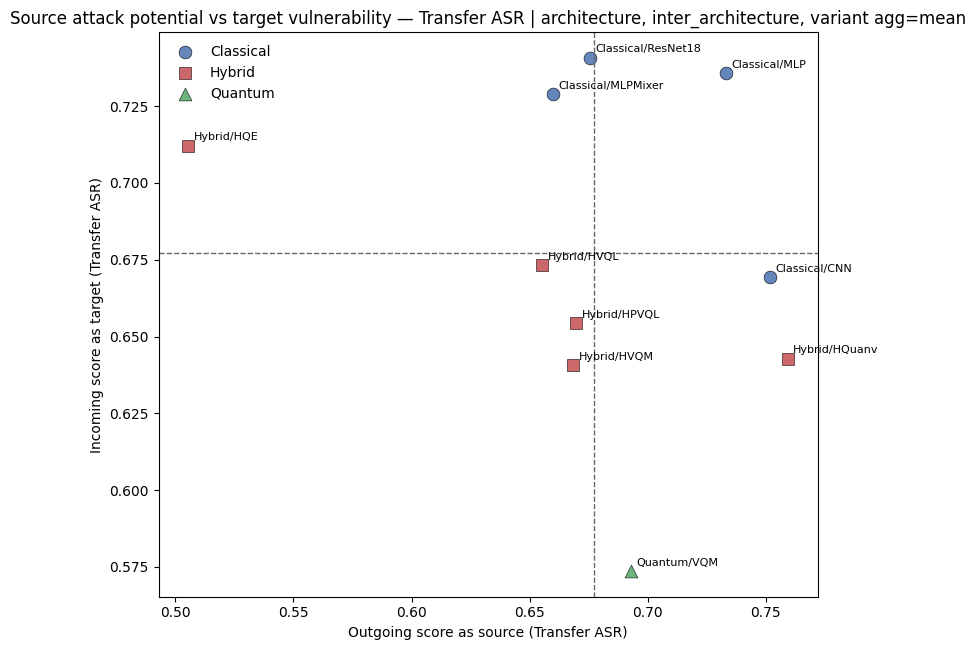

In [5]:

fig, ax = plot_source_target_scatter(
    profile,
    title=(
        f"Source attack potential vs target vulnerability — {CONFIG.metric} | "
        f"{CONFIG.source_grain}, {CONFIG.comparison_mode}, "
        f"variant agg={CONFIG.variant_aggregate_mode}"
    ),
    annotate=True,
)
fig_path = save_figure(fig, OUT_DIR / f"{prefix}.png")
fig_path
